# LeetCode #174: Dungeon Game

https://leetcode.com/problems/dungeon-game/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Forward DP (incorrect) | N/A | N/A |
| Backward DP ★ | O(m×n) | O(m×n) or O(n) |

## Understanding the Methods
### Why Forward DP Fails
Going forward, you don't know if a high-health path now will have enough health later. The minimum health depends on future cells, not past accumulation.

### Optimal: Backward DP ★
Work backwards from the princess (bottom-right). dp[i][j] = minimum health needed when entering cell (i,j) to reach the princess alive. At each cell: need = max(1, min(dp[i+1][j], dp[i][j+1]) - dungeon[i][j]). The answer is dp[0][0].

## Solutions
### C#

In [ ]:
public class Solution {
    public int CalculateMinimumHP(int[][] dungeon) {
        int m = dungeon.Length, n = dungeon[0].Length;
        var dp = new int[m + 1][];
        for (int i = 0; i <= m; i++) {
            dp[i] = new int[n + 1];
            Array.Fill(dp[i], int.MaxValue);
        }
        dp[m][n - 1] = dp[m - 1][n] = 1;
        for (int i = m - 1; i >= 0; i--) {
            for (int j = n - 1; j >= 0; j--) {
                int need = Math.Min(dp[i + 1][j], dp[i][j + 1]) - dungeon[i][j];
                dp[i][j] = Math.Max(1, need);
            }
        }
        return dp[0][0];
    }
}

### Python

In [ ]:
from typing import List

class Solution:
    def calculateMinimumHP(self, dungeon: List[List[int]]) -> int:
        m, n = len(dungeon), len(dungeon[0])
        INF = float('inf')
        dp = [[INF] * (n + 1) for _ in range(m + 1)]
        dp[m][n - 1] = dp[m - 1][n] = 1
        for i in range(m - 1, -1, -1):
            for j in range(n - 1, -1, -1):
                need = min(dp[i + 1][j], dp[i][j + 1]) - dungeon[i][j]
                dp[i][j] = max(1, need)
        return dp[0][0]

### Go

In [ ]:
package main

import (
    "fmt"
    "math"
)

func calculateMinimumHP(dungeon [][]int) int {
    m, n := len(dungeon), len(dungeon[0])
    dp := make([][]int, m+1)
    for i := range dp {
        dp[i] = make([]int, n+1)
        for j := range dp[i] {
            dp[i][j] = math.MaxInt32
        }
    }
    dp[m][n-1] = 1
    dp[m-1][n] = 1
    for i := m - 1; i >= 0; i-- {
        for j := n - 1; j >= 0; j-- {
            need := min(dp[i+1][j], dp[i][j+1]) - dungeon[i][j]
            if need < 1 {
                need = 1
            }
            dp[i][j] = need
        }
    }
    return dp[0][0]
}

func min(a, b int) int {
    if a < b { return a }
    return b
}

func main() {
    dungeon := [][]int{{-2,-3,3},{-5,-10,1},{10,30,-5}}
    fmt.Println(calculateMinimumHP(dungeon)) // 7
}

### Rust

In [ ]:
pub struct Solution;

impl Solution {
    pub fn calculate_minimum_hp(dungeon: Vec<Vec<i32>>) -> i32 {
        let m = dungeon.len();
        let n = dungeon[0].len();
        let mut dp = vec![vec![i32::MAX; n + 1]; m + 1];
        dp[m][n - 1] = 1;
        dp[m - 1][n] = 1;
        for i in (0..m).rev() {
            for j in (0..n).rev() {
                let need = dp[i + 1][j].min(dp[i][j + 1]) - dungeon[i][j];
                dp[i][j] = need.max(1);
            }
        }
        dp[0][0]
    }
}

## Example Scenarios

### 1. Common Case — Classic 3&times;3 Dungeon
**Input:** `dungeon = [[-2,-3,3],[-5,-10,1],[10,30,-5]]`
Working backward, $dp[i][j] = \max(1,\ \min(dp[i{+}1][j], dp[i][j{+}1]) - dungeon[i][j])$. The best path right-right-down-down needs $dp[0][0] = 7$ starting health.

### 2. Slightly Complex — Negatives Force a Buffer
**Input:** `dungeon = [[1,-3,3],[0,-2,0],[-3,-3,-3]]`
Health must stay $\ge 1$ in every cell, so the trailing $-3$s raise the requirement. Backward DP gives $dp[0][0] = 3$.

### 3. Edge Case: Time Factor — Larger 3&times;4 Grid
**Input:** `dungeon = [[-2,-3,3,1],[-5,-10,1,-1],[10,30,-5,2]]`
Every one of the $m\times n$ cells is filled exactly once, so cost scales as $O(mn)$. Answer $dp[0][0] = 6$.

### 4. Edge Case: Space Factor — Single Row, O(n) DP
**Input:** `dungeon = [[-3,5,-2,1]]`
With one row the DP collapses to a 1-D array of width $n$. Accumulating the needed buffer right to left yields $4$.

### 5. Almost-Impossible but Plausible — One Lethal Cell
**Input:** `dungeon = [[-5]]`
A single room that drains $5$ HP: the knight needs $\max(1, 1-(-5)) = 6$ to survive with at least $1$ HP. Output $6$.


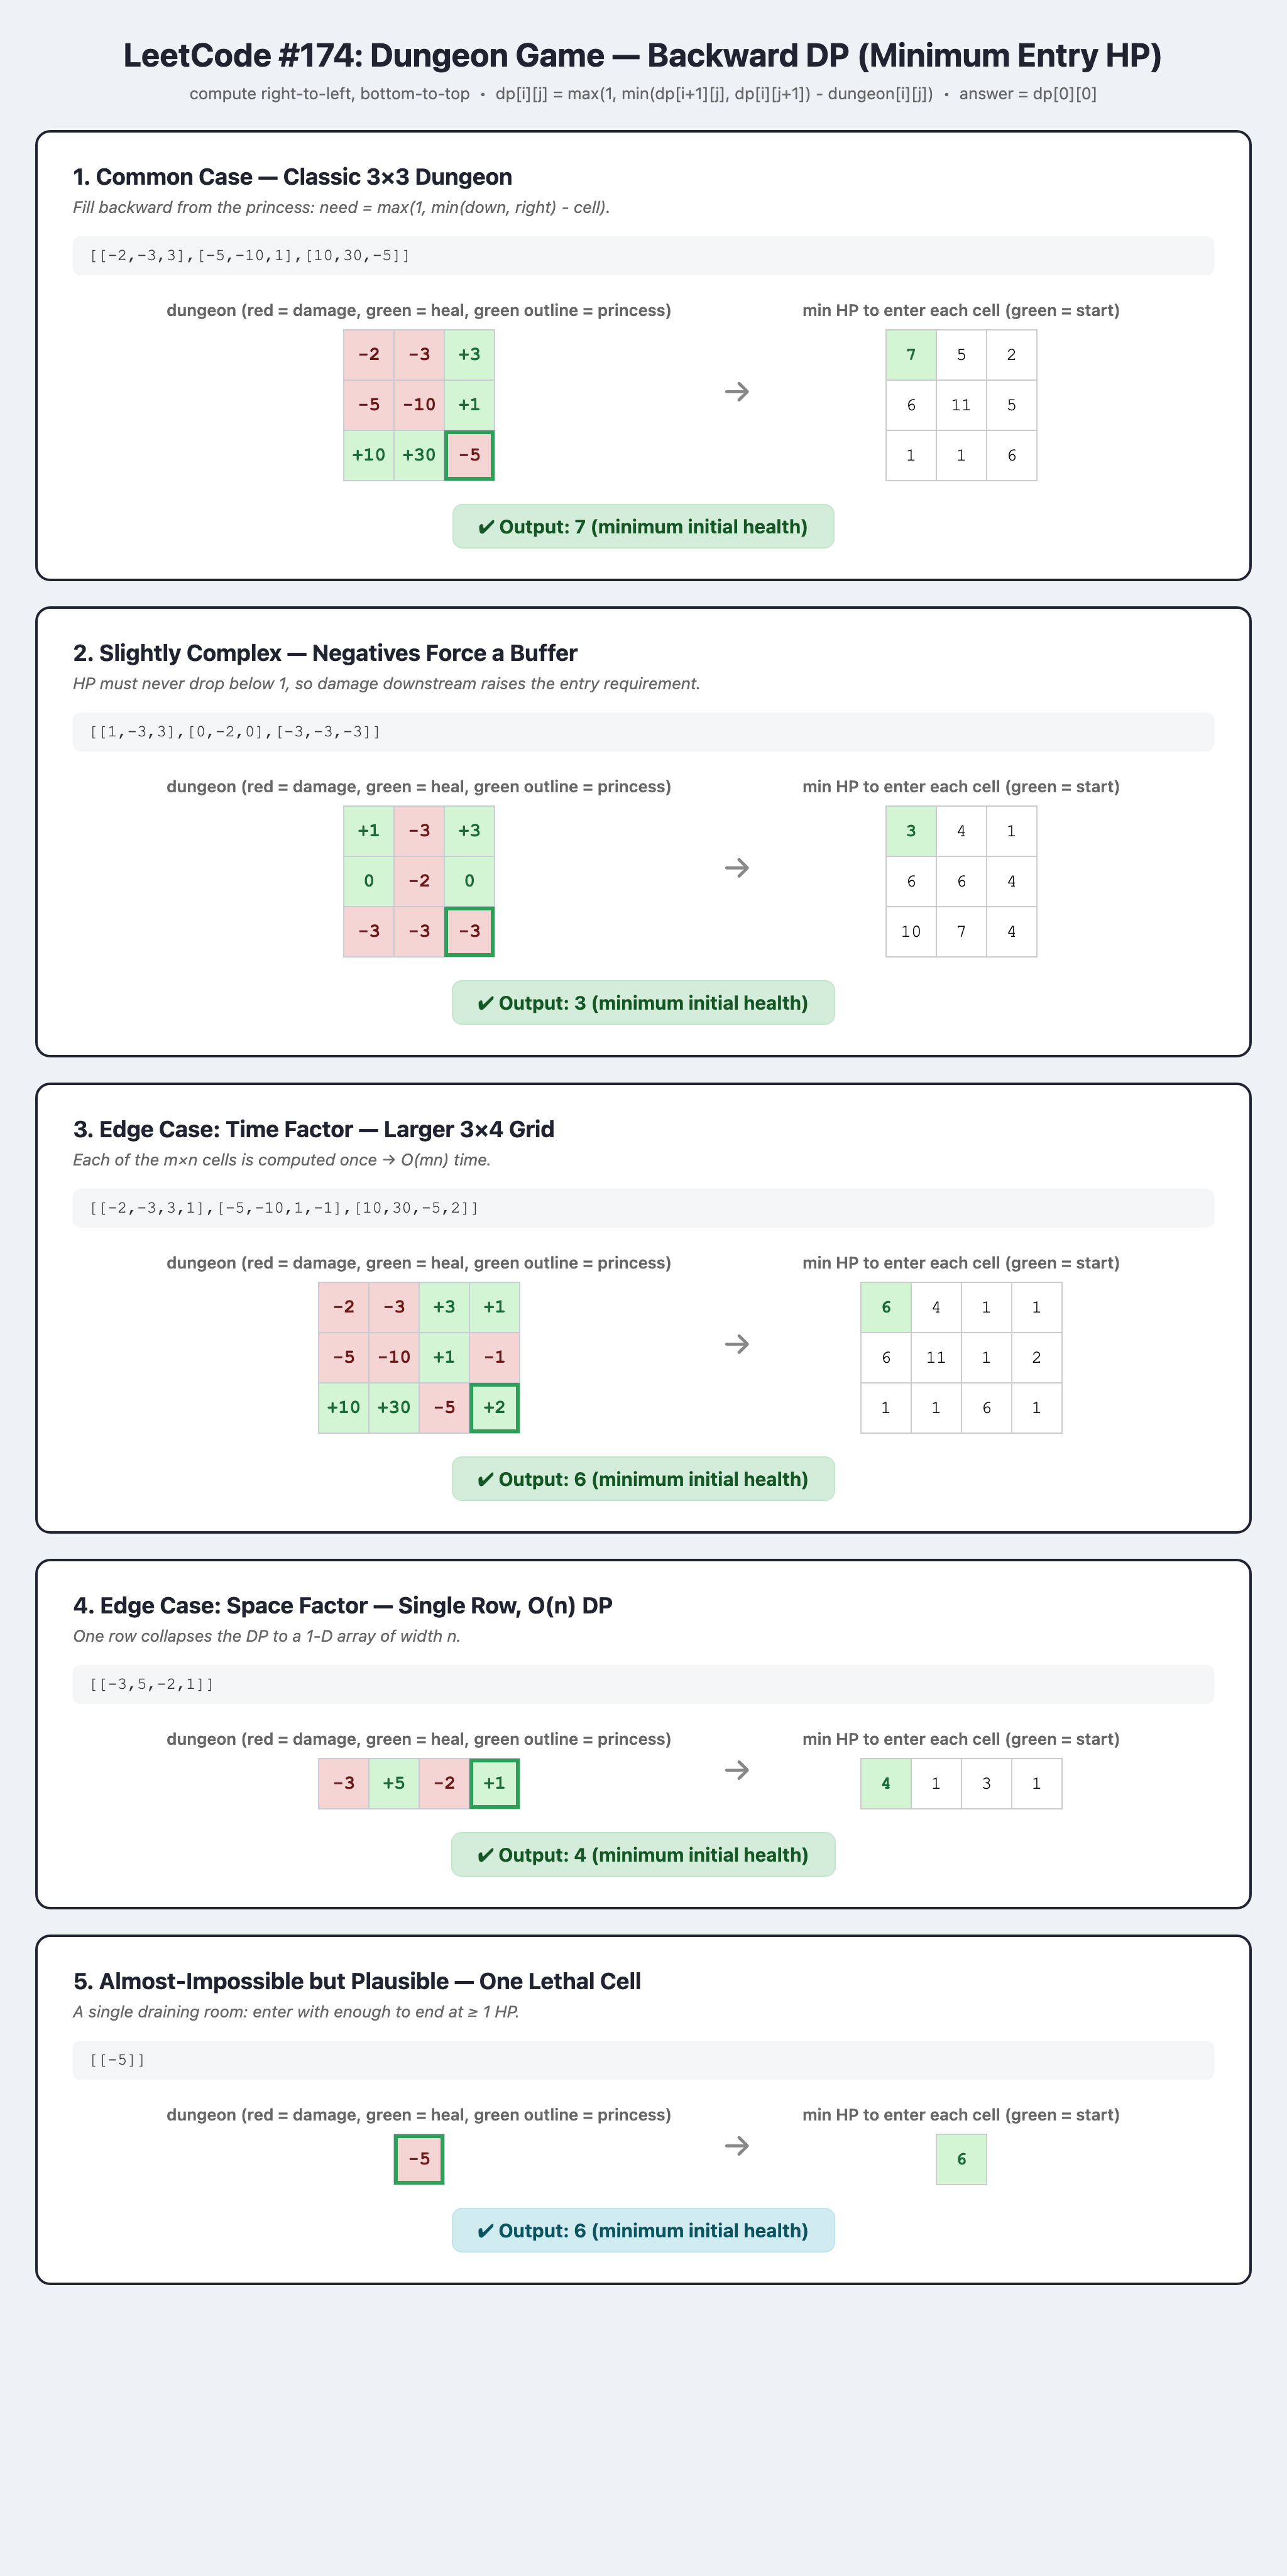